In [1]:
import os, random, time, json, copy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from PIL import Image
import shutil

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch:", torch.__version__)

device: cuda | torch: 2.11.0+cu130


In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)                  # Python built-in
    np.random.seed(seed)               # NumPy
    torch.manual_seed(seed)            # PyTorch (CPU)
    torch.cuda.manual_seed_all(seed)   # PyTorch (semua GPU)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

In [3]:
# Download Dataset
ROOT = "./data"
ds_trainval = datasets.OxfordIIITPet(root=ROOT, split="trainval", target_types="category", download=True)
ds_test     = datasets.OxfordIIITPet(root=ROOT, split="test",     target_types="category", download=True)

print(len(ds_trainval), len(ds_test))
print(ds_trainval.classes == ds_test.classes, len(ds_trainval.classes))
print(ds_trainval.classes)

100%|██████████| 792M/792M [00:20<00:00, 37.8MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 9.59MB/s]


3680 3669
True 37
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


In [4]:
# Subsetting
CHOSEN = ["Abyssinian", "Bengal", "Persian", "Russian Blue", "Siamese",   # kucing
          "Beagle", "Boxer", "Chihuahua", "Pug", "Samoyed"]               # anjing

all_classes = ds_trainval.classes
assert all(c in all_classes for c in CHOSEN), "ada nama kelas yang tidak cocok, cek daftar di Sel 3"

old2new = {all_classes.index(c): i for i, c in enumerate(CHOSEN)}   # label asli (0-36) -> label baru (0-9)

paths, labels = [], []
for ds in (ds_trainval, ds_test):
    for p, y in zip(ds._images, ds._labels):
        if y in old2new:
            paths.append(str(p))
            labels.append(old2new[y])

labels = np.array(labels)
print("total gambar:", len(paths))
print(pd.Series(labels).value_counts().sort_index().rename(index=dict(enumerate(CHOSEN))))

total gambar: 1996
Abyssinian      198
Bengal          200
Persian         200
Russian Blue    200
Siamese         199
Beagle          200
Boxer           199
Chihuahua       200
Pug             200
Samoyed         200
Name: count, dtype: int64


In [5]:
# Train test split
idx = np.arange(len(labels))

train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=labels, random_state=SEED)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)

print("train/val/test:", len(train_idx), len(val_idx), len(test_idx))

# periksa proporsi kelas tiap set
for name, ids in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    counts = pd.Series(labels[ids]).value_counts().sort_index()
    print(name, counts.values.tolist())

# pastikan tidak ada irisan (anti data leakage)
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

# simpan bukti split
pd.DataFrame({
    "path": paths, "label": labels,
    "split": ["train" if i in set(train_idx) else "val" if i in set(val_idx) else "test" for i in idx]
}).to_csv("split_info.csv", index=False)

train/val/test: 1397 299 300
train [139, 140, 140, 140, 139, 140, 139, 140, 140, 140]
val [29, 30, 30, 30, 30, 30, 30, 30, 30, 30]
test [30, 30, 30, 30, 30, 30, 30, 30, 30, 30]


In [6]:
# Starter Code (Data Augmentation)
weights = models.ResNet18_Weights.IMAGENET1K_V1

# Val/test (dan skenario "tanpa augmentasi" di B4): deterministik
eval_transforms = weights.transforms()

# Train dengan augmentasi
train_transforms_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean,
                         std=weights.transforms().std),
])

# Train tanpa augmentasi: sama dengan eval
train_transforms_noaug = eval_transforms

print(eval_transforms)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [7]:
class PetSubset(Dataset):
    def __init__(self, paths, labels, indices, transform):
        self.paths = [paths[i] for i in indices]
        self.labels = [int(labels[i]) for i in indices]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]


BATCH_SIZE = 32

def make_loaders(train_tf):
    g = torch.Generator()
    g.manual_seed(SEED)
    train_ds = PetSubset(paths, labels, train_idx, train_tf)
    val_ds   = PetSubset(paths, labels, val_idx,   eval_transforms)
    test_ds  = PetSubset(paths, labels, test_idx,  eval_transforms)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, generator=g)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    return train_loader, val_loader, test_loader

In [8]:
train_loader, val_loader, test_loader = make_loaders(train_transforms_aug)

x, y = next(iter(train_loader))
print("batch:", x.shape, y.shape)                      # harapan: [32, 3, 224, 224] dan [32]
print("label min/max:", y.min().item(), y.max().item())  # harapan: dalam 0..9
print("mean/std batch:", x.mean().item(), x.std().item())

# Val deterministik: gambar yang sama -> keluaran yang sama
img = Image.open(paths[val_idx[0]]).convert("RGB")
print("eval deterministik:", torch.equal(eval_transforms(img), eval_transforms(img)))

# Train acak: gambar yang sama -> keluaran beda
print("train acak (harus False):", torch.equal(train_transforms_aug(img), train_transforms_aug(img)))

batch: torch.Size([32, 3, 224, 224]) torch.Size([32])
label min/max: 0 9
mean/std batch: -0.24800607562065125 1.249686598777771
eval deterministik: True
train acak (harus False): False


In [9]:
# Build Model dan Optimizer
NUM_CLASSES = 10

def build_model(kind):
    """kind: 'B1' (scratch), 'B2' (feature extraction), 'B3' (fine-tune layer4)."""
    model = models.resnet18(weights=None if kind == "B1" else weights)

    if kind in ("B2", "B3"):
        for p in model.parameters():          # bekukan seluruh backbone
            p.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)   # head baru (requires_grad=True)

    if kind == "B3":
        for p in model.layer4.parameters():   # buka layer4
            p.requires_grad = True
    return model.to(device)


def build_optimizer(model, kind):
    if kind == "B1":
        groups = [{"params": model.parameters(), "lr": 1e-3}]
    elif kind == "B2":
        groups = [{"params": model.fc.parameters(), "lr": 1e-3}]
    elif kind == "B3":
        groups = [{"params": model.layer4.parameters(), "lr": 1e-4},
                  {"params": model.fc.parameters(),     "lr": 1e-3}]
    return torch.optim.AdamW(groups, weight_decay=1e-2)


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total


def set_train_mode(model):
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()          # BN beku -> statistik ImageNet tidak ikut bergeser

In [10]:
# EfficientNet
if "_build_model_resnet" not in globals():          # guard: aman kalau sel dijalankan dua kali
    _build_model_resnet = build_model
    _build_optimizer_resnet = build_optimizer

def build_model(kind):
    if kind.startswith("E_"):                       # EfficientNet-B0
        w = models.EfficientNet_B0_Weights.IMAGENET1K_V1
        model = models.efficientnet_b0(weights=w)
        for p in model.parameters():                # bekukan semuanya
            p.requires_grad = False
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)   # head baru
        if kind == "E_B3":                          # buka blok terakhir
            for p in model.features[7:].parameters():
                p.requires_grad = True
        return model.to(device)
    return _build_model_resnet(kind)

def build_optimizer(model, kind):
    if kind == "E_B2":
        groups = [{"params": model.classifier.parameters(), "lr": 1e-3}]
    elif kind == "E_B3":
        groups = [{"params": model.features[7:].parameters(), "lr": 1e-4},
                  {"params": model.classifier.parameters(),   "lr": 1e-3}]
    else:
        return _build_optimizer_resnet(model, kind)
    return torch.optim.AdamW(groups, weight_decay=1e-2)

def set_train_mode(model):
    model.train()
    for m in model.modules():                       # aturan lama: BN beku -> eval
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()
    if hasattr(model, "features"):                  # aturan baru: blok EfficientNet yang beku -> eval
        for blk in model.features:
            if not any(p.requires_grad for p in blk.parameters()):
                blk.eval()

In [11]:
# Verification
for kind in ["B1", "B2", "B3"]:
    m = build_model(kind)
    print(kind, "trainable/total:", count_params(m))

m = build_model("B3")
set_train_mode(m)
print("BN layer1 (beku) training?  :", m.layer1[0].bn1.training)   # harapan: False
print("BN layer4 (dilatih) training?:", m.layer4[0].bn1.training)   # harapan: True

B1 trainable/total: (11181642, 11181642)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 127MB/s]


B2 trainable/total: (5130, 11181642)
B3 trainable/total: (8398858, 11181642)
BN layer1 (beku) training?  : False
BN layer4 (dilatih) training?: True


In [12]:
for k in ["E_B2", "E_B3"]:
    m = build_model(k)
    print(k, "trainable/total:", count_params(m))

m = build_model("E_B3"); set_train_mode(m)
print("blok 0 (beku) training? :", m.features[0].training)   # : False
print("blok 7 (dilatih) training?:", m.features[7].training)  # correct: True
print("head training?          :", m.classifier.training)     # correct: True

print(models.EfficientNet_B0_Weights.IMAGENET1K_V1.transforms())

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s] 


E_B2 trainable/total: (12810, 4020358)
E_B3 trainable/total: (1142202, 4020358)
blok 0 (beku) training? : False
blok 7 (dilatih) training?: True
head training?          : True
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)


In [13]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    set_train_mode(model) if training else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps, probs = [], [], []
    for x, y in loader:
        out = model(x.to(device))
        p = torch.softmax(out, dim=1)
        ys.append(y); ps.append(p.argmax(1).cpu()); probs.append(p.max(1).values.cpu())
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()

In [14]:
PATIENCE = 5
MAX_EPOCHS = 30
epoch_rows   = pd.read_csv("epoch_log.csv").to_dict("records")       if os.path.exists("epoch_log.csv")       else []
summary_rows = pd.read_csv("summary_metrics.csv").to_dict("records") if os.path.exists("summary_metrics.csv") else []

def run_experiment(name, kind, train_tf, augmentation):
    set_seed()
    epoch_rows[:] = [r for r in epoch_rows if r["experiment"] != name]
    summary_rows[:] = [r for r in summary_rows if r["experiment"] != name]                                        # tiap eksperimen mulai dari seed yang sama
    train_loader, val_loader, test_loader = make_loaders(train_tf)
    train_eval_loader = DataLoader(PetSubset(paths, labels, train_idx, eval_transforms),
                                   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    model = build_model(kind)
    trainable, total = count_params(model)            # verifikasi SEBELUM optimizer dibentuk
    optimizer = build_optimizer(model, kind)
    lrs = [g["lr"] for g in optimizer.param_groups]
    print(f"[{name}] trainable {trainable:,} / {total:,} | lr per grup: {lrs}")

    best_val_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        epoch_rows.append(dict(experiment=name, epoch=epoch, train_loss=tr_loss, val_loss=va_loss,
                               train_acc=tr_acc, val_acc=va_acc))
        print(f"  ep {epoch:2d} | train {tr_loss:.4f}/{tr_acc:.3f} | val {va_loss:.4f}/{va_acc:.3f}")

        if va_loss < best_val_loss:
            best_val_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"  early stopping di epoch {epoch} (terbaik: epoch {best_epoch})")
                break

    if device.type == "cuda": torch.cuda.synchronize()
    duration = time.time() - t0

    model.load_state_dict(best_state)                 # kembalikan ke bobot terbaik
    best_row = epoch_rows[-(epoch - best_epoch) - 1]
    y_te, p_te, _ = predict(model, test_loader)
    y_tr, p_tr, _ = predict(model, train_eval_loader)

    summary_rows.append(dict(
        experiment=name, strategy=kind, augmentation=augmentation,
        trainable_params=trainable, total_params=total, lr_per_group=str(lrs),
        epochs_run=epoch, epochs_to_converge=best_epoch, train_time_sec=round(duration, 1),
        train_acc_logged=best_row["train_acc"], train_acc_clean=float((y_tr == p_tr).mean()),
        val_loss=best_row["val_loss"], val_acc=best_row["val_acc"],
        test_acc=float((y_te == p_te).mean()),
        test_macro_f1=f1_score(y_te, p_te, average="macro"), seed=SEED))

    pd.DataFrame(summary_rows).to_csv("summary_metrics.csv", index=False)
    pd.DataFrame(epoch_rows).to_csv("epoch_log.csv", index=False)
    torch.save(best_state, f"{name}_best.pt")
    print(pd.DataFrame(summary_rows).iloc[-1].to_string())
    return model

# B2:

In [15]:
model_B2 = run_experiment("B2_feature_extraction", "B2", train_transforms_aug, augmentation=True)

[B2_feature_extraction] trainable 5,130 / 11,181,642 | lr per grup: [0.001]
  ep  1 | train 1.2222/0.687 | val 0.5057/0.910
  ep  2 | train 0.3861/0.947 | val 0.2681/0.967
  ep  3 | train 0.2606/0.952 | val 0.2220/0.943
  ep  4 | train 0.1961/0.969 | val 0.1690/0.970
  ep  5 | train 0.1721/0.966 | val 0.1422/0.977
  ep  6 | train 0.1481/0.970 | val 0.1365/0.977
  ep  7 | train 0.1290/0.971 | val 0.1210/0.983
  ep  8 | train 0.1120/0.981 | val 0.1178/0.977
  ep  9 | train 0.1027/0.979 | val 0.1052/0.980
  ep 10 | train 0.0997/0.981 | val 0.1214/0.970
  ep 11 | train 0.1008/0.974 | val 0.1001/0.967
  ep 12 | train 0.0900/0.980 | val 0.1010/0.983
  ep 13 | train 0.0839/0.979 | val 0.0910/0.983
  ep 14 | train 0.0768/0.982 | val 0.0937/0.980
  ep 15 | train 0.0738/0.982 | val 0.0836/0.980
  ep 16 | train 0.0772/0.983 | val 0.0883/0.980
  ep 17 | train 0.0660/0.986 | val 0.0960/0.973
  ep 18 | train 0.0644/0.988 | val 0.0981/0.977
  ep 19 | train 0.0607/0.987 | val 0.0834/0.987
  ep 20 | tr

# B1 dan B3:

In [16]:
model_B1 = run_experiment("B1_scratch",       "B1", train_transforms_aug, augmentation=True)
model_B3 = run_experiment("B3_finetune",      "B3", train_transforms_aug, augmentation=True)

[B1_scratch] trainable 11,181,642 / 11,181,642 | lr per grup: [0.001]
  ep  1 | train 2.3224/0.175 | val 3.2808/0.177
  ep  2 | train 2.0129/0.279 | val 1.8958/0.385
  ep  3 | train 1.8823/0.351 | val 2.0447/0.284
  ep  4 | train 1.7944/0.380 | val 2.4875/0.331
  ep  5 | train 1.6665/0.422 | val 3.9111/0.254
  ep  6 | train 1.5532/0.472 | val 1.9041/0.385
  ep  7 | train 1.5481/0.460 | val 1.8331/0.391
  ep  8 | train 1.4412/0.508 | val 1.7769/0.418
  ep  9 | train 1.4047/0.528 | val 1.4693/0.522
  ep 10 | train 1.3267/0.560 | val 2.8149/0.388
  ep 11 | train 1.2209/0.583 | val 1.7588/0.478
  ep 12 | train 1.1867/0.593 | val 1.5153/0.515
  ep 13 | train 1.1168/0.621 | val 2.0149/0.408
  ep 14 | train 1.1284/0.622 | val 1.3903/0.569
  ep 15 | train 0.9851/0.651 | val 1.6350/0.518
  ep 16 | train 0.9023/0.693 | val 1.8423/0.475
  ep 17 | train 0.9097/0.687 | val 1.2707/0.572
  ep 18 | train 0.8717/0.702 | val 2.1917/0.408
  ep 19 | train 0.8394/0.695 | val 1.2441/0.599
  ep 20 | train 0.

# B4:

In [17]:
model_B4_B2 = run_experiment("B4_B2_noaug", "B2", train_transforms_noaug, augmentation=False)

[B4_B2_noaug] trainable 5,130 / 11,181,642 | lr per grup: [0.001]
  ep  1 | train 1.0932/0.747 | val 0.4465/0.936
  ep  2 | train 0.2948/0.961 | val 0.2520/0.970
  ep  3 | train 0.1841/0.974 | val 0.1906/0.987
  ep  4 | train 0.1359/0.982 | val 0.1624/0.970
  ep  5 | train 0.1099/0.986 | val 0.1362/0.977
  ep  6 | train 0.0915/0.989 | val 0.1240/0.977
  ep  7 | train 0.0797/0.991 | val 0.1140/0.980
  ep  8 | train 0.0678/0.993 | val 0.1064/0.983
  ep  9 | train 0.0589/0.995 | val 0.0999/0.980
  ep 10 | train 0.0529/0.996 | val 0.0975/0.983
  ep 11 | train 0.0486/0.994 | val 0.0945/0.980
  ep 12 | train 0.0419/0.999 | val 0.0916/0.980
  ep 13 | train 0.0384/0.998 | val 0.0860/0.980
  ep 14 | train 0.0353/0.999 | val 0.0858/0.980
  ep 15 | train 0.0324/1.000 | val 0.0822/0.980
  ep 16 | train 0.0317/0.999 | val 0.0821/0.980
  ep 17 | train 0.0271/0.999 | val 0.0858/0.980
  ep 18 | train 0.0248/1.000 | val 0.0792/0.980
  ep 19 | train 0.0243/0.999 | val 0.0802/0.977
  ep 20 | train 0.0225

# **B5**: **Arsitektur** **Pembanding**

In [18]:
# B5: EfficientNet-B0. Strategi mengikuti pemenang B2 vs B3 berdasarkan VAL LOSS (bukan test)
s = pd.read_csv("summary_metrics.csv")
cand = s[s["experiment"].isin(["B2_feature_extraction", "B3_finetune"])]
assert len(cand) == 2, "B2 dan B3 harus sudah dijalankan sebelum B5"
print(cand[["experiment", "val_loss", "val_acc"]].round(4))

winner = cand.sort_values("val_loss").iloc[0]["experiment"]
b5_kind = "E_B3" if winner == "B3_finetune" else "E_B2"
print("pemenang ResNet-18 (val_loss):", winner, "-> B5 memakai", b5_kind)

model_B5 = run_experiment("B5_efficientnet_b0", b5_kind, train_transforms_aug, augmentation=True)

              experiment  val_loss  val_acc
0  B2_feature_extraction    0.0727   0.9799
2            B3_finetune    0.0696   0.9799
pemenang ResNet-18 (val_loss): B3_finetune -> B5 memakai E_B3
[B5_efficientnet_b0] trainable 1,142,202 / 4,020,358 | lr per grup: [0.0001, 0.001]
  ep  1 | train 0.9394/0.823 | val 0.1417/0.993
  ep  2 | train 0.1451/0.974 | val 0.0655/0.993
  ep  3 | train 0.0878/0.983 | val 0.0519/0.997
  ep  4 | train 0.0580/0.986 | val 0.0416/0.993
  ep  5 | train 0.0378/0.994 | val 0.0395/0.990
  ep  6 | train 0.0370/0.991 | val 0.0379/0.987
  ep  7 | train 0.0305/0.994 | val 0.0365/0.990
  ep  8 | train 0.0198/0.998 | val 0.0339/0.993
  ep  9 | train 0.0198/0.996 | val 0.0335/0.990
  ep 10 | train 0.0195/0.995 | val 0.0386/0.993
  ep 11 | train 0.0166/0.998 | val 0.0340/0.993
  ep 12 | train 0.0126/0.998 | val 0.0330/0.993
  ep 13 | train 0.0152/0.996 | val 0.0360/0.993
  ep 14 | train 0.0065/1.000 | val 0.0356/0.993
  ep 15 | train 0.0075/1.000 | val 0.0328/0.993
  

# C1:

In [19]:
summary = pd.read_csv("summary_metrics.csv")
summary["overfit_gap"] = summary["train_acc_clean"] - summary["val_acc"]

cols = ["experiment", "strategy", "augmentation", "trainable_params", "lr_per_group",
        "epochs_to_converge", "train_time_sec", "train_acc_clean", "val_acc",
        "overfit_gap", "test_macro_f1"]
table = summary[cols].round(4)
display(table)
table.to_csv("tabel_konsolidasi.csv", index=False)

,experiment,strategy,augmentation,trainable_params,lr_per_group,epochs_to_converge,train_time_sec,train_acc_clean,val_acc,overfit_gap,test_macro_f1
0,B2_feature_extraction,B2,True,5130,[0.001],24,383.7,0.9928,0.9799,0.0129,0.9610
1,B1_scratch,B1,True,11181642,[0.001],20,364.1,0.7015,0.6221,0.0794,0.5946
2,B3_finetune,B3,True,8398858,"[0.0001, 0.001]",4,123.0,0.9971,0.9799,0.0172,0.9701
3,B4_B2_noaug,B2,False,5130,[0.001],29,285.4,1.0000,0.9799,0.0201,0.9606
4,B5_efficientnet_b0,E_B3,True,1142202,"[0.0001, 0.001]",15,270.1,1.0000,0.9933,0.0067,0.9835


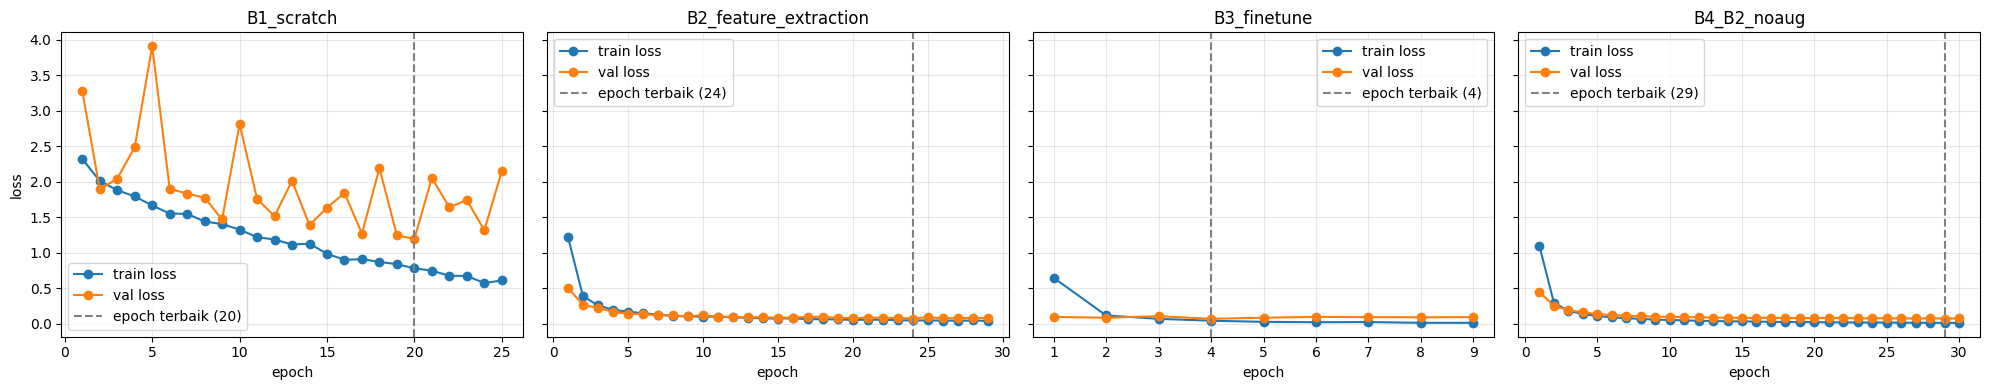

In [20]:
import matplotlib.pyplot as plt

log = pd.read_csv("epoch_log.csv")
# Gunakan nama eksperimen yang benar-benar ada di file summary
names = [name for name in ["B1_scratch", "B2_feature_extraction", "B3_finetune", "B4_B2_noaug"] if name in summary["experiment"].values]
required = ["B1_scratch", "B2_feature_extraction", "B3_finetune"]
missing = [n for n in required if n not in summary["experiment"].values]
if missing:
    print("PERINGATAN, belum ada di log:", missing)
fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4), sharey=True)
if len(names) == 1:
    axes = [axes]

for ax, name in zip(axes, names):
    d = log[log["experiment"] == name]
    ax.plot(d["epoch"], d["train_loss"], marker="o", label="train loss")
    ax.plot(d["epoch"], d["val_loss"],   marker="o", label="val loss")
    best = summary.loc[summary["experiment"] == name, "epochs_to_converge"].iloc[0]
    ax.axvline(best, color="gray", linestyle="--", label=f"epoch terbaik ({best})")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.savefig("kurva_loss_B1_B2_B3.png", dpi=150)
plt.show()

In [21]:
s = pd.read_csv("summary_metrics.csv")
s["sec_per_epoch"] = s["train_time_sec"] / s["epochs_run"]

b5_kind = s.loc[s["experiment"] == "B5_efficientnet_b0", "strategy"].iloc[0]
counterpart = "B3_finetune" if b5_kind == "E_B3" else "B2_feature_extraction"

cmp = s[s["experiment"].isin([counterpart, "B5_efficientnet_b0"])]
cols = ["experiment", "trainable_params", "total_params", "epochs_to_converge",
        "sec_per_epoch", "train_time_sec", "val_acc", "test_macro_f1"]
display(cmp[cols].round(4))
cmp[cols].round(4).to_csv("tabel_B5_vs_resnet.csv", index=False)

,experiment,trainable_params,total_params,epochs_to_converge,sec_per_epoch,train_time_sec,val_acc,test_macro_f1
2,B3_finetune,8398858,11181642,4,13.6667,123.0,0.9799,0.9701
4,B5_efficientnet_b0,1142202,4020358,15,13.5050,270.1,0.9933,0.9835


# C3:

In [22]:
print(s.sort_values("val_loss")[["experiment", "strategy", "val_loss", "val_acc", "test_acc", "test_macro_f1"]].round(4))
best_name = s.sort_values("val_loss").iloc[0]["experiment"]
best_kind = s.loc[s["experiment"] == best_name, "strategy"].iloc[0]
print("model terbaik (val_loss):", best_name, best_kind)

              experiment strategy  val_loss  val_acc  test_acc  test_macro_f1
4     B5_efficientnet_b0     E_B3    0.0328   0.9933    0.9833         0.9835
2            B3_finetune       B3    0.0696   0.9799    0.9700         0.9701
0  B2_feature_extraction       B2    0.0727   0.9799    0.9600         0.9610
3            B4_B2_noaug       B2    0.0735   0.9799    0.9600         0.9606
1             B1_scratch       B1    1.1964   0.6221    0.5900         0.5946
model terbaik (val_loss): B5_efficientnet_b0 E_B3


test acc : 0.9833 | log: 0.9833
macro F1 : 0.9835 | log: 0.9835
jumlah kesalahan: 5 dari 300
pasangan (aktual -> prediksi): [(('Bengal', 'Abyssinian'), 1), (('Russian Blue', 'Abyssinian'), 1), (('Pug', 'Boxer'), 1), (('Abyssinian', 'Bengal'), 1), (('Siamese', 'Abyssinian'), 1)]


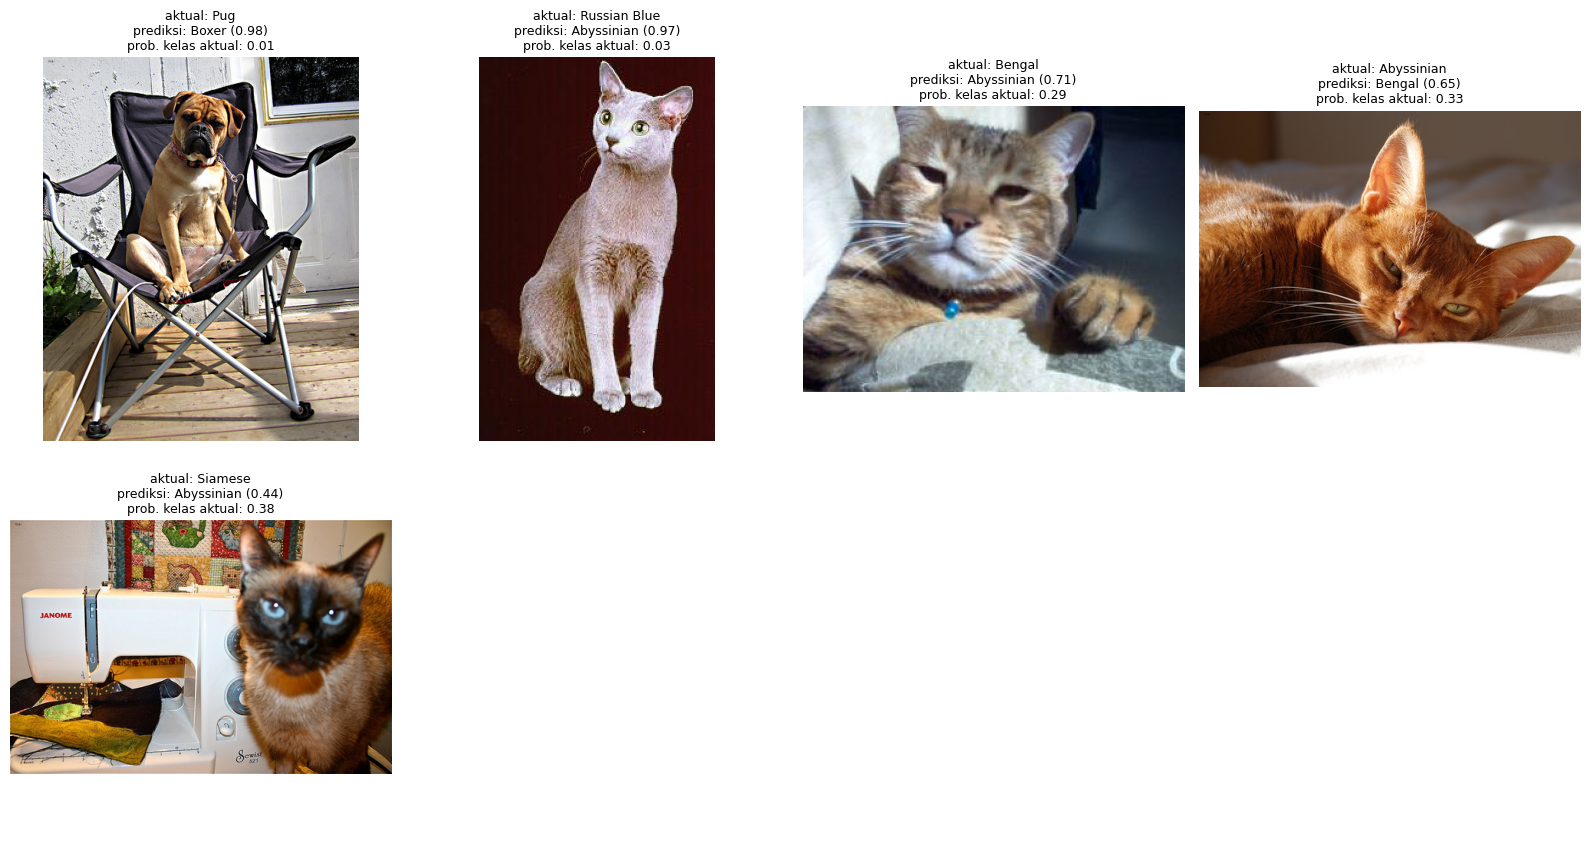

   test_pos                                            path        actual  \
0       127          data/oxford-iiit-pet/images/pug_74.jpg           Pug   
1        88  data/oxford-iiit-pet/images/Russian_Blue_8.jpg  Russian Blue   
2        67      data/oxford-iiit-pet/images/Bengal_143.jpg        Bengal   
3       197  data/oxford-iiit-pet/images/Abyssinian_150.jpg    Abyssinian   
4       242     data/oxford-iiit-pet/images/Siamese_150.jpg       Siamese   

    predicted  confidence  prob_actual_class  
0       Boxer       0.983              0.012  
1  Abyssinian       0.972              0.028  
2  Abyssinian       0.714              0.286  
3      Bengal       0.653              0.335  
4  Abyssinian       0.436              0.377  


In [23]:
import matplotlib.pyplot as plt
from collections import Counter

model = build_model(best_kind)
model.load_state_dict(torch.load(f"{best_name}_best.pt", map_location=device))
model.eval()

_, _, test_loader = make_loaders(train_transforms_aug)

@torch.no_grad()
def predict_full(model, loader):
    P = []
    for x, _ in loader:
        P.append(torch.softmax(model(x.to(device)), dim=1).cpu())
    return torch.cat(P).numpy()

probs  = predict_full(model, test_loader)          # [n_test, 10]
y_true = labels[test_idx]                          # urutan sama dengan test_loader (shuffle=False)
y_pred = probs.argmax(1)

ref = s[s["experiment"] == best_name].iloc[0]
print("test acc :", round(float((y_pred == y_true).mean()), 4), "| log:", round(ref["test_acc"], 4))
print("macro F1 :", round(f1_score(y_true, y_pred, average="macro"), 4), "| log:", round(ref["test_macro_f1"], 4))

err = np.where(y_pred != y_true)[0]
print("jumlah kesalahan:", len(err), "dari", len(y_true))
print("pasangan (aktual -> prediksi):",
      Counter((CHOSEN[y_true[i]], CHOSEN[y_pred[i]]) for i in err).most_common())

# aturan pemilihan: urutkan dari keyakinan tertinggi pada prediksi yang salah, ambil maksimal 8
err = err[np.argsort(-probs[err, y_pred[err]])]
show = err[:8]

rows = []
ncols = 4; nrows = int(np.ceil(max(len(show), 1) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.3 * nrows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), show):
    img = Image.open(paths[test_idx[i]]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"aktual: {CHOSEN[y_true[i]]}\nprediksi: {CHOSEN[y_pred[i]]} ({probs[i, y_pred[i]]:.2f})\n"
                 f"prob. kelas aktual: {probs[i, y_true[i]]:.2f}", fontsize=9)
    rows.append(dict(test_pos=int(i), path=paths[test_idx[i]], actual=CHOSEN[y_true[i]],
                     predicted=CHOSEN[y_pred[i]], confidence=float(probs[i, y_pred[i]]),
                     prob_actual_class=float(probs[i, y_true[i]])))
plt.tight_layout()
plt.savefig("failure_analysis.png", dpi=150)
plt.show()

pd.DataFrame(rows).to_csv("failure_cases.csv", index=False)
print(pd.DataFrame(rows).round(3))

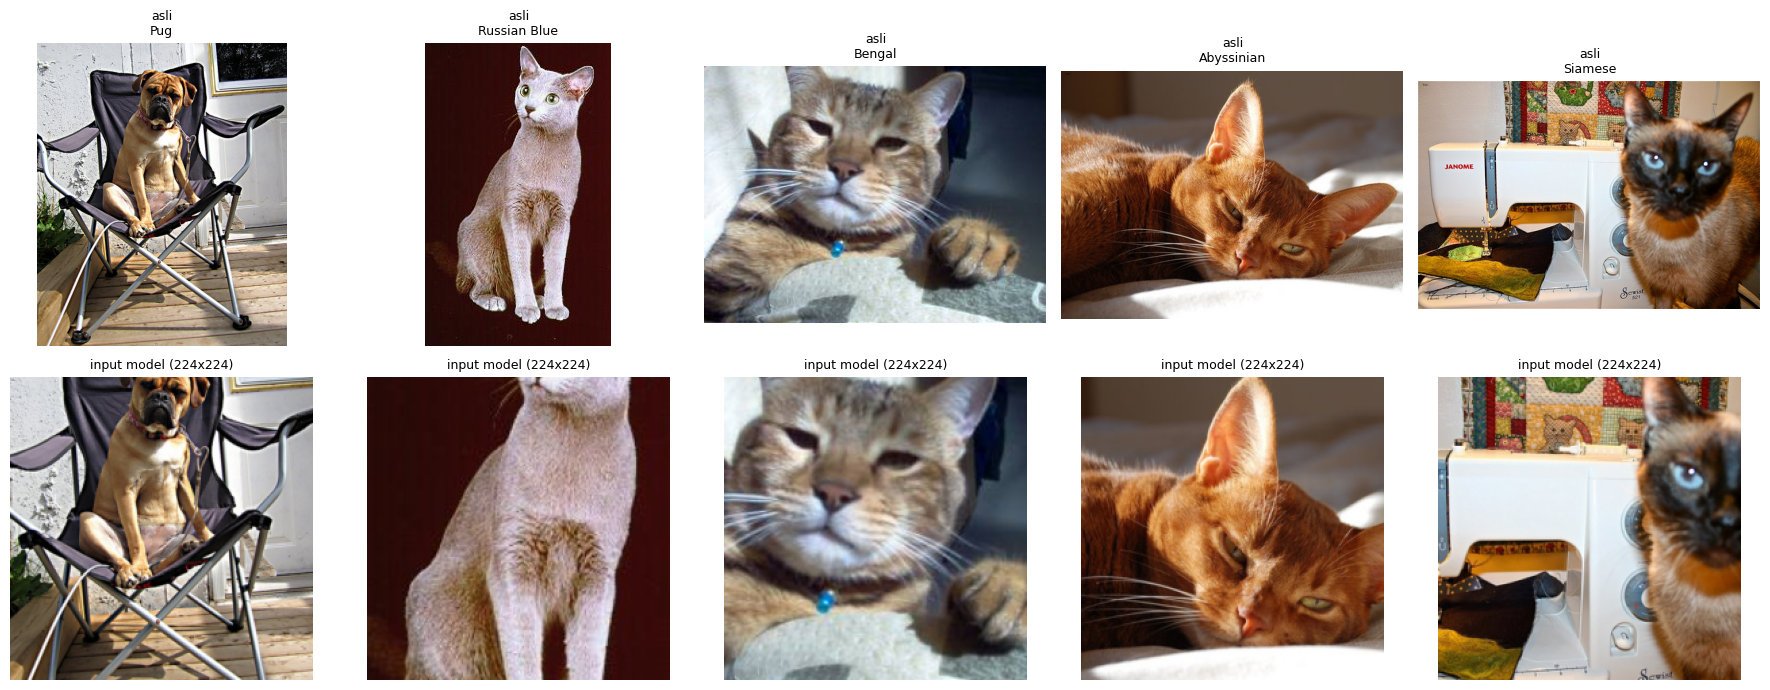

In [24]:
mean = torch.tensor(eval_transforms.mean).view(3, 1, 1)
std  = torch.tensor(eval_transforms.std).view(3, 1, 1)

fig, axes = plt.subplots(2, len(show), figsize=(3.6 * len(show), 7), squeeze=False)
for j, i in enumerate(show):
    img = Image.open(paths[test_idx[i]]).convert("RGB")
    axes[0][j].imshow(img);  axes[0][j].set_title(f"asli\n{CHOSEN[y_true[i]]}", fontsize=9)
    inp = (eval_transforms(img) * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    axes[1][j].imshow(inp);  axes[1][j].set_title("input model (224x224)", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig("failure_model_input.png", dpi=130)
plt.show()

# C5:

In [25]:
import torch.nn.functional as F

pre = models.resnet18(weights=weights).to(device)     # ImageNet asli, tidak pernah dilatih di sini
b2 = build_model("B2"); b2.load_state_dict(torch.load("B2_feature_extraction_best.pt", map_location=device))
b3 = build_model("B3"); b3.load_state_dict(torch.load("B3_finetune_best.pt", map_location=device))
for m in (pre, b2, b3):
    m.eval()

def same_state(m1, m2, prefixes):
    s1, s2 = m1.state_dict(), m2.state_dict()
    return all(torch.equal(s1[k], s2[k]) for k in s1 if k.startswith(prefixes))

frozen = ("conv1", "bn1", "layer1", "layer2", "layer3")
print("B2 backbone == pretrained :", same_state(pre, b2, frozen + ("layer4",)))   # harapan: True
print("B3 layer1-3 == pretrained :", same_state(pre, b3, frozen))                  # harapan: True
print("B3 layer4  == pretrained  :", same_state(pre, b3, ("layer4",)))             # harapan: False

# seberapa jauh bobot layer4 bergeser (relatif terhadap norma bobot awal)
d = sum(((a - b) ** 2).sum() for a, b in zip(b3.layer4.parameters(), pre.layer4.parameters())).sqrt()
n = sum((b ** 2).sum() for b in pre.layer4.parameters()).sqrt()
print("pergeseran relatif bobot layer4:", round((d / n).item(), 4))

# kemiripan fitur 512-d (setelah global pooling) antara pretrained dan B3
def pooled(model, loader):
    m = copy.deepcopy(model); m.fc = nn.Identity(); m.eval()
    out = []
    with torch.no_grad():
        for x, _ in loader:
            out.append(m(x.to(device)).cpu())
    return torch.cat(out)

_, _, test_loader = make_loaders(train_transforms_aug)
cos = F.cosine_similarity(pooled(pre, test_loader), pooled(b3, test_loader), dim=1)
print("cosine fitur pretrained vs B3: mean", round(cos.mean().item(), 4), "| min", round(cos.min().item(), 4))

B2 backbone == pretrained : True
B3 layer1-3 == pretrained : True
B3 layer4  == pretrained  : False
pergeseran relatif bobot layer4: 0.0592
cosine fitur pretrained vs B3: mean 0.8062 | min 0.6821


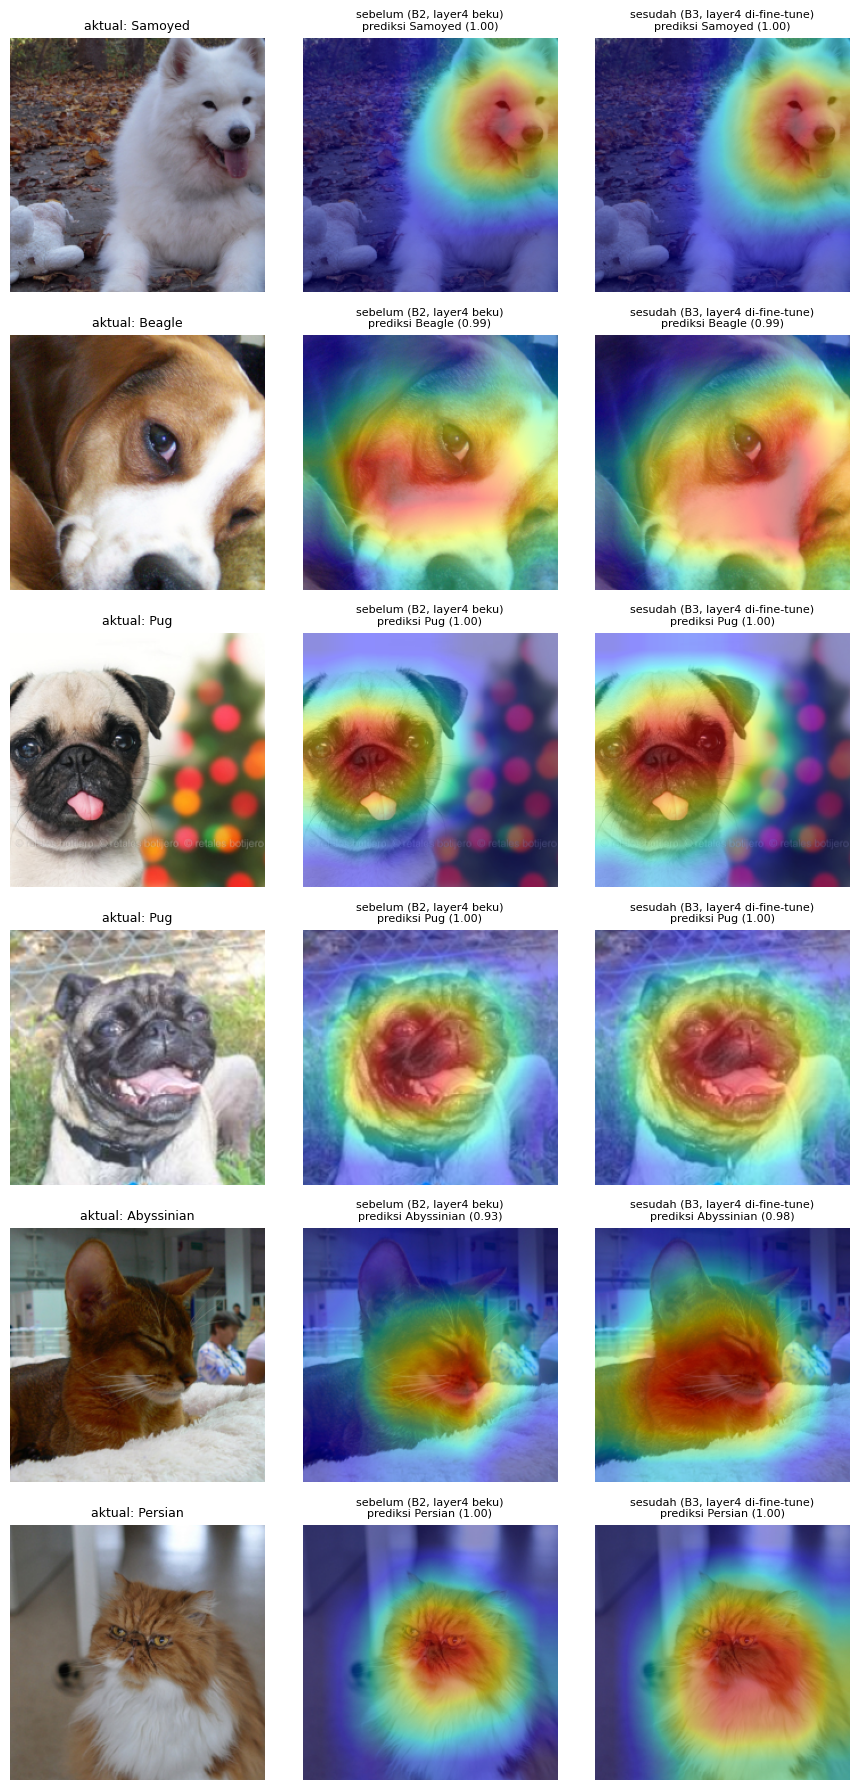

In [26]:
test_ds = PetSubset(paths, labels, test_idx, eval_transforms)
mean = torch.tensor(eval_transforms.mean).view(3, 1, 1)
std  = torch.tensor(eval_transforms.std).view(3, 1, 1)

def gradcam(model, x, target):
    model.eval()
    store = {}
    h = model.layer4.register_forward_hook(lambda m, i, o: store.update(a=o))
    x = x.clone().requires_grad_(True)          # perlu agar grafik gradien ada walau backbone beku
    with torch.enable_grad():
        out = model(x)
        h.remove()
        grad = torch.autograd.grad(out[0, target], store["a"])[0]
    w = grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), torch.softmax(out, 1)[0].detach().cpu()

# aturan pemilihan sampel: 6 gambar test acak (seed tetap), bukan dipilih manual
rng = np.random.default_rng(SEED)
cases = sorted(rng.choice(len(test_ds), size=6, replace=False).tolist())

fig, axes = plt.subplots(len(cases), 3, figsize=(9, 3 * len(cases)), squeeze=False)
for r, i in enumerate(cases):
    x, y = test_ds[i]
    xb = x.unsqueeze(0).to(device)
    base = (x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    axes[r][0].imshow(base); axes[r][0].set_title(f"aktual: {CHOSEN[y]}", fontsize=9)
    for c, (nm, mdl) in enumerate([("sebelum (B2, layer4 beku)", b2), ("sesudah (B3, layer4 di-fine-tune)", b3)], start=1):
        cam, p = gradcam(mdl, xb, y)               # target = kelas aktual, sama untuk kedua model
        axes[r][c].imshow(base); axes[r][c].imshow(cam, cmap="jet", alpha=0.45)
        axes[r][c].set_title(f"{nm}\nprediksi {CHOSEN[p.argmax().item()]} ({p.max():.2f})", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig("gradcam_before_after.png", dpi=130)
plt.show()

In [27]:
c5 = dict(
    B2_backbone_equals_pretrained=bool(same_state(pre, b2, frozen + ("layer4",))),
    B3_layer1_3_equals_pretrained=bool(same_state(pre, b3, frozen)),
    B3_layer4_equals_pretrained=bool(same_state(pre, b3, ("layer4",))),
    layer4_relative_shift=round((d / n).item(), 4),
    cosine_feature_mean=round(cos.mean().item(), 4),
    cosine_feature_min=round(cos.min().item(), 4),
    gradcam_cases_test_positions=cases,
    seed=SEED,
)
json.dump(c5, open("c5_metrics.json", "w"), indent=2)
print(c5)

{'B2_backbone_equals_pretrained': True, 'B3_layer1_3_equals_pretrained': True, 'B3_layer4_equals_pretrained': False, 'layer4_relative_shift': 0.0592, 'cosine_feature_mean': 0.8062, 'cosine_feature_min': 0.6821, 'gradcam_cases_test_positions': [26, 129, 130, 194, 229, 257], 'seed': 42}


# Export:

In [28]:
shutil.rmtree("hasil_tugas05", ignore_errors=True)
os.makedirs("hasil_tugas05", exist_ok=True)

In [29]:
import shutil, glob
from google.colab import files

keep = ["summary_metrics.csv", "epoch_log.csv", "split_info.csv", "tabel_konsolidasi.csv",
        "tabel_B5_vs_resnet.csv", "failure_cases.csv", "c5_metrics.json"] \
       + glob.glob("*.png") + glob.glob("*_best.pt")
os.makedirs("hasil_tugas05", exist_ok=True)
for f in keep:
    if os.path.exists(f):
        shutil.copy(f, "hasil_tugas05/")
print(sorted(os.listdir("hasil_tugas05")))

shutil.make_archive("hasil_tugas05", "zip", "hasil_tugas05")
files.download("hasil_tugas05.zip")

['B1_scratch_best.pt', 'B2_feature_extraction_best.pt', 'B3_finetune_best.pt', 'B4_B2_noaug_best.pt', 'B5_efficientnet_b0_best.pt', 'c5_metrics.json', 'epoch_log.csv', 'failure_analysis.png', 'failure_cases.csv', 'failure_model_input.png', 'gradcam_before_after.png', 'kurva_loss_B1_B2_B3.png', 'split_info.csv', 'summary_metrics.csv', 'tabel_B5_vs_resnet.csv', 'tabel_konsolidasi.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>